<a href="https://colab.research.google.com/github/Fata-Haidar/PCVK_Ganjil_2026/blob/main/pertemuan7/week8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**D1 Tugas Individu**

**1. Tautkan dengan Google Drive**

In [7]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


**2. Import Library**

In [9]:
#Library yang digunakan
import cv2 as cv
from google.colab.patches import cv2_imshow
import numpy as np
import math
import pandas as pd
import matplotlib.pyplot as plt
from collections import deque
from scipy import ndimage as ndi
from skimage import data, filters, color, segmentation, feature, morphology
from skimage.filters import gaussian
from skimage.segmentation import flood

**3. Global Threshold Manual (T = 200)**

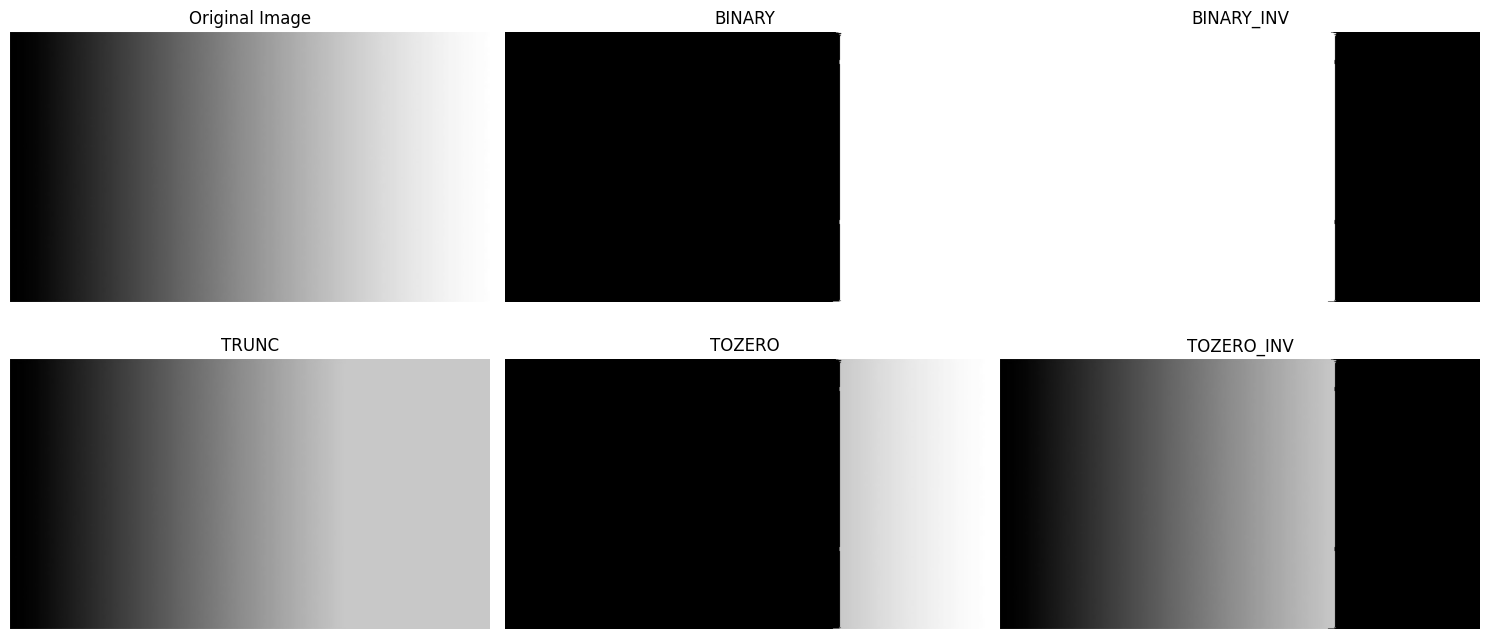

In [21]:
BASE = '/content/drive/MyDrive/PCVK'

filename = f'{BASE}/gradient.jpg'
img = cv.imread(filename, cv.IMREAD_GRAYSCALE)

# Parameter threshold
thresh = 200
maxval = 255

# 1. Binary Threshold
thresh1 = np.where(img > thresh, maxval, 0).astype(np.uint8)

# 2. Binary Inverse Threshold
thresh2 = np.where(img > thresh, 0, maxval).astype(np.uint8)

# 3. Truncate Threshold
thresh3 = np.where(img > thresh, thresh, img).astype(np.uint8)

# 4. Threshold To Zero
thresh4 = np.where(img > thresh, img, 0).astype(np.uint8)

# 5. Threshold To Zero Inverse
thresh5 = np.where(img > thresh, 0, img).astype(np.uint8)

# Menampilkan hasil
titles = [
    'Original Image',
    'BINARY',
    'BINARY_INV',
    'TRUNC',
    'TOZERO',
    'TOZERO_INV'
]

images = [img, thresh1, thresh2, thresh3, thresh4, thresh5]

plt.figure(figsize=(15, 7))

for i in range(len(images)):
    plt.subplot(2, 3, i + 1)
    plt.imshow(images[i], cmap='gray', vmin=0, vmax=255)
    plt.title(titles[i])
    plt.axis('off')

plt.tight_layout()
plt.show()

**4. Adaptive Threshold Manual**

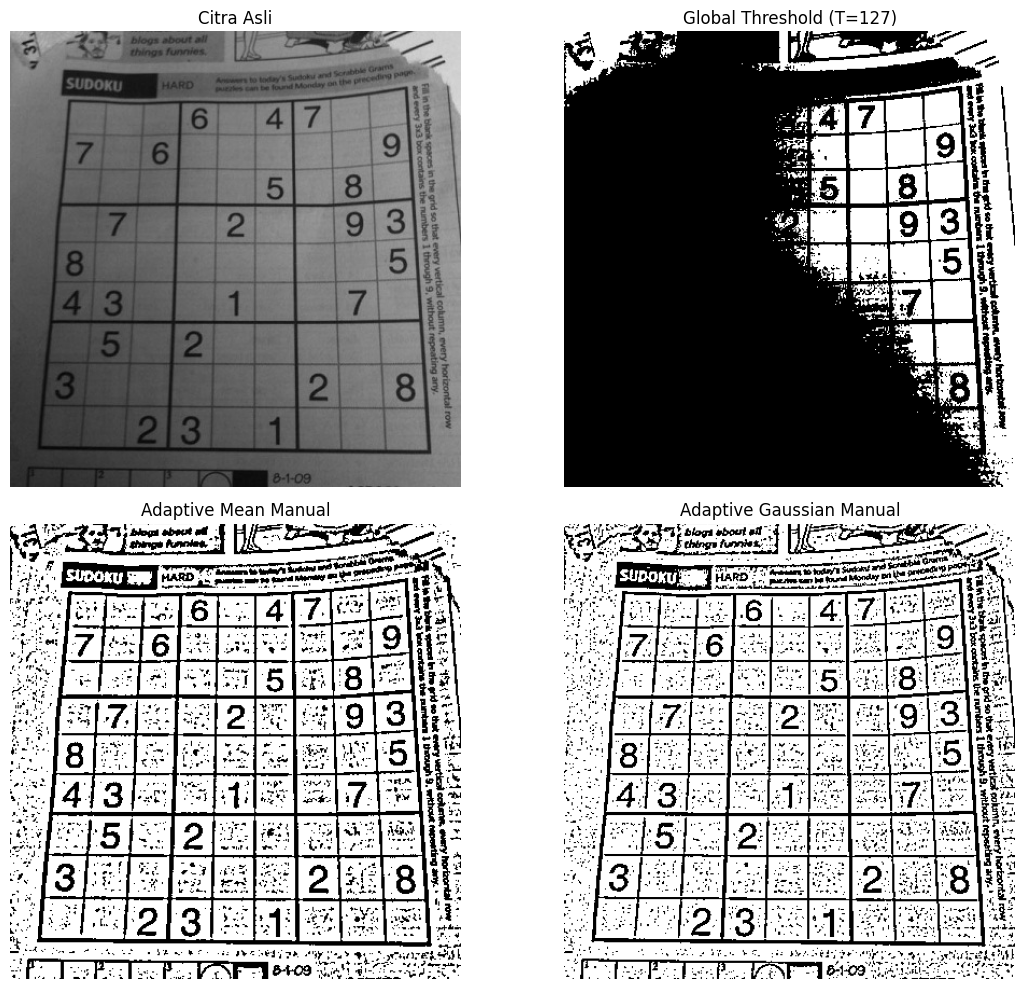

In [20]:
# Lokasi gambar
BASE = '/content/drive/MyDrive/PCVK'

# Membaca citra Sudoku
filename = f'{BASE}/sudoku-original.jpg'
gray = cv.imread(filename, cv.IMREAD_GRAYSCALE)

if gray is None:
    raise FileNotFoundError(filename)

# Parameter
thresh = 127
block_size = 11
C = 2
sigma = 2

# Fungsi filtering manual
def filter_manual(img, kernel, axis):
    img = img.astype(np.float64)
    radius = len(kernel) // 2
    h, w = img.shape

    if axis == 0:
        padded = np.pad(
            img, ((radius, radius), (0, 0)),
            mode='reflect'
        )
    else:
        padded = np.pad(
            img, ((0, 0), (radius, radius)),
            mode='reflect'
        )

    result = np.zeros((h, w), dtype=np.float64)

    for i, weight in enumerate(kernel):
        if axis == 0:
            result += weight * padded[i:i+h, :]
        else:
            result += weight * padded[:, i:i+w]

    return result

# 1. Global Threshold Manual
global_thresh = np.where(
    gray > thresh, 255, 0
).astype(np.uint8)

# 2. Adaptive Mean Manual
mean_kernel = np.ones(block_size) / block_size

mean_temp = filter_manual(gray, mean_kernel, axis=0)
mean_local = filter_manual(mean_temp, mean_kernel, axis=1)

adaptive_mean = np.where(
    gray > (mean_local - C), 255, 0
).astype(np.uint8)

# 3. Adaptive Gaussian Manual
x = np.arange(
    -(block_size // 2),
    block_size // 2 + 1
)

gaussian_kernel = np.exp(
    -(x**2) / (2 * sigma**2)
)

gaussian_kernel = gaussian_kernel / gaussian_kernel.sum()

gaussian_temp = filter_manual(
    gray, gaussian_kernel, axis=0
)

gaussian_local = filter_manual(
    gaussian_temp, gaussian_kernel, axis=1
)

adaptive_gaussian = np.where(
    gray > (gaussian_local - C), 255, 0
).astype(np.uint8)

# Menampilkan hasil
titles = [
    'Citra Asli',
    'Global Threshold (T=127)',
    'Adaptive Mean Manual',
    'Adaptive Gaussian Manual'
]

images = [
    gray,
    global_thresh,
    adaptive_mean,
    adaptive_gaussian
]

plt.figure(figsize=(12, 10))

for i in range(4):
    plt.subplot(2, 2, i + 1)
    plt.imshow(images[i], cmap='gray', vmin=0, vmax=255)
    plt.title(titles[i])
    plt.axis('off')

plt.tight_layout()
plt.show()


**5A. Otsu Thresholding Manual (Lena)**

Global Threshold = 127
Otsu Threshold = 92
Intensitas minimum = 85
Intensitas maksimum = 108


/tmp/ipykernel_785/1556585052.py:66: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.9; the parameter will become keyword-only in 3.11.
  plt.hist(blur.ravel(), 256, [0, 256])


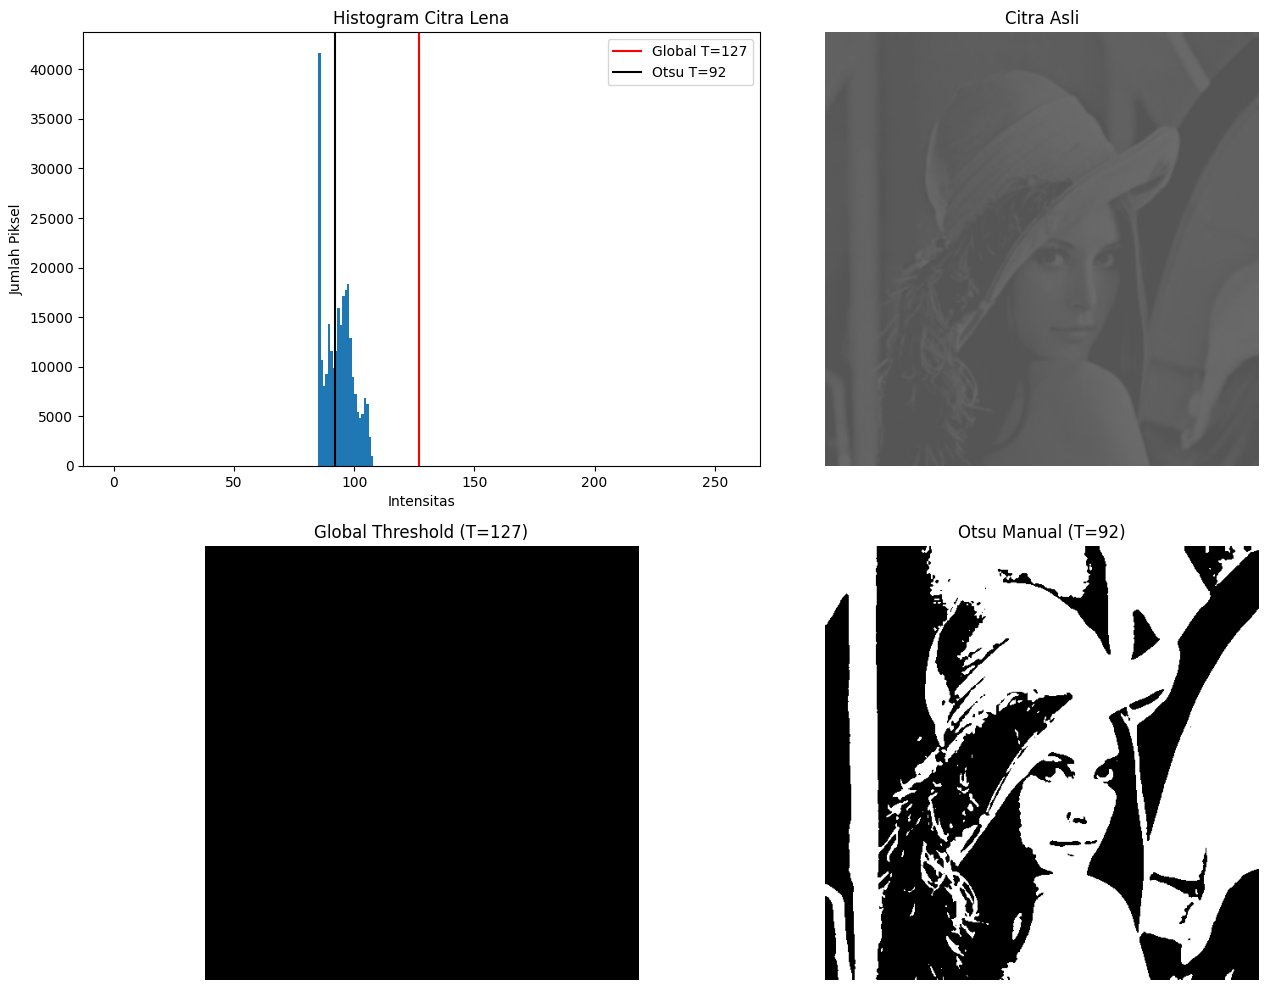

In [19]:

# Lokasi gambar
BASE = '/content/drive/MyDrive/PCVK'

# Membaca citra Lena
filename = f'{BASE}/lena_gs_lc2.jpg'
img = cv.imread(filename, 0)

if img is None:
    raise FileNotFoundError(filename)

blur = cv.GaussianBlur(img, (5, 5), 0)
thresh = 127

# Fungsi Otsu Manual
def otsu_manual(gray):
    pixel_number = gray.shape[0] * gray.shape[1]
    hist, bins = np.histogram(gray, np.arange(257))

    final_thresh = 0
    final_value = -1

    intensity_arr = np.arange(256)

    for t in range(256):
        pcb = np.sum(hist[:t+1])
        pcf = np.sum(hist[t+1:])

        if pcb == 0 or pcf == 0:
            continue

        Wb = pcb / pixel_number
        Wf = pcf / pixel_number

        mub = np.sum(intensity_arr[:t+1] * hist[:t+1]) / pcb
        muf = np.sum(intensity_arr[t+1:] * hist[t+1:]) / pcf

        value = Wb * Wf * (mub - muf) ** 2

        if value > final_value:
            final_thresh = t
            final_value = value

    final_img = np.where(
        gray > final_thresh, 255, 0
    ).astype(np.uint8)

    return final_img, final_thresh

# Global Threshold Manual
global_thresh = np.where(
    blur > thresh, 255, 0
).astype(np.uint8)

# Otsu Threshold Manual
otsu_biner, otsu_thresh = otsu_manual(blur)

print("Global Threshold =", thresh)
print("Otsu Threshold =", otsu_thresh)
print("Intensitas minimum =", blur.min())
print("Intensitas maksimum =", blur.max())

# Menampilkan Histogram dan Hasil
plt.figure(figsize=(14, 10))

plt.subplot(2, 2, 1)
plt.hist(blur.ravel(), 256, [0, 256])
plt.axvline(thresh, color='red', label='Global T=127')
plt.axvline(otsu_thresh, color='black',
            label=f'Otsu T={otsu_thresh}')
plt.title('Histogram Citra Lena')
plt.xlabel('Intensitas')
plt.ylabel('Jumlah Piksel')
plt.legend()

titles = [
    'Citra Asli',
    'Global Threshold (T=127)',
    f'Otsu Manual (T={otsu_thresh})'
]

images = [blur, global_thresh, otsu_biner]

for i in range(3):
    plt.subplot(2, 2, i + 2)
    plt.imshow(images[i], cmap='gray', vmin=0, vmax=255)
    plt.title(titles[i])
    plt.axis('off')

plt.tight_layout()
plt.show()


**5B. Otsu Thresholding pada KTP**

Global Threshold = 127
Otsu Threshold = 99
Intensitas minimum = 4
Intensitas maksimum = 254


/tmp/ipykernel_785/2362689069.py:26: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.9; the parameter will become keyword-only in 3.11.
  plt.hist(blur.ravel(), 256, [0, 256])


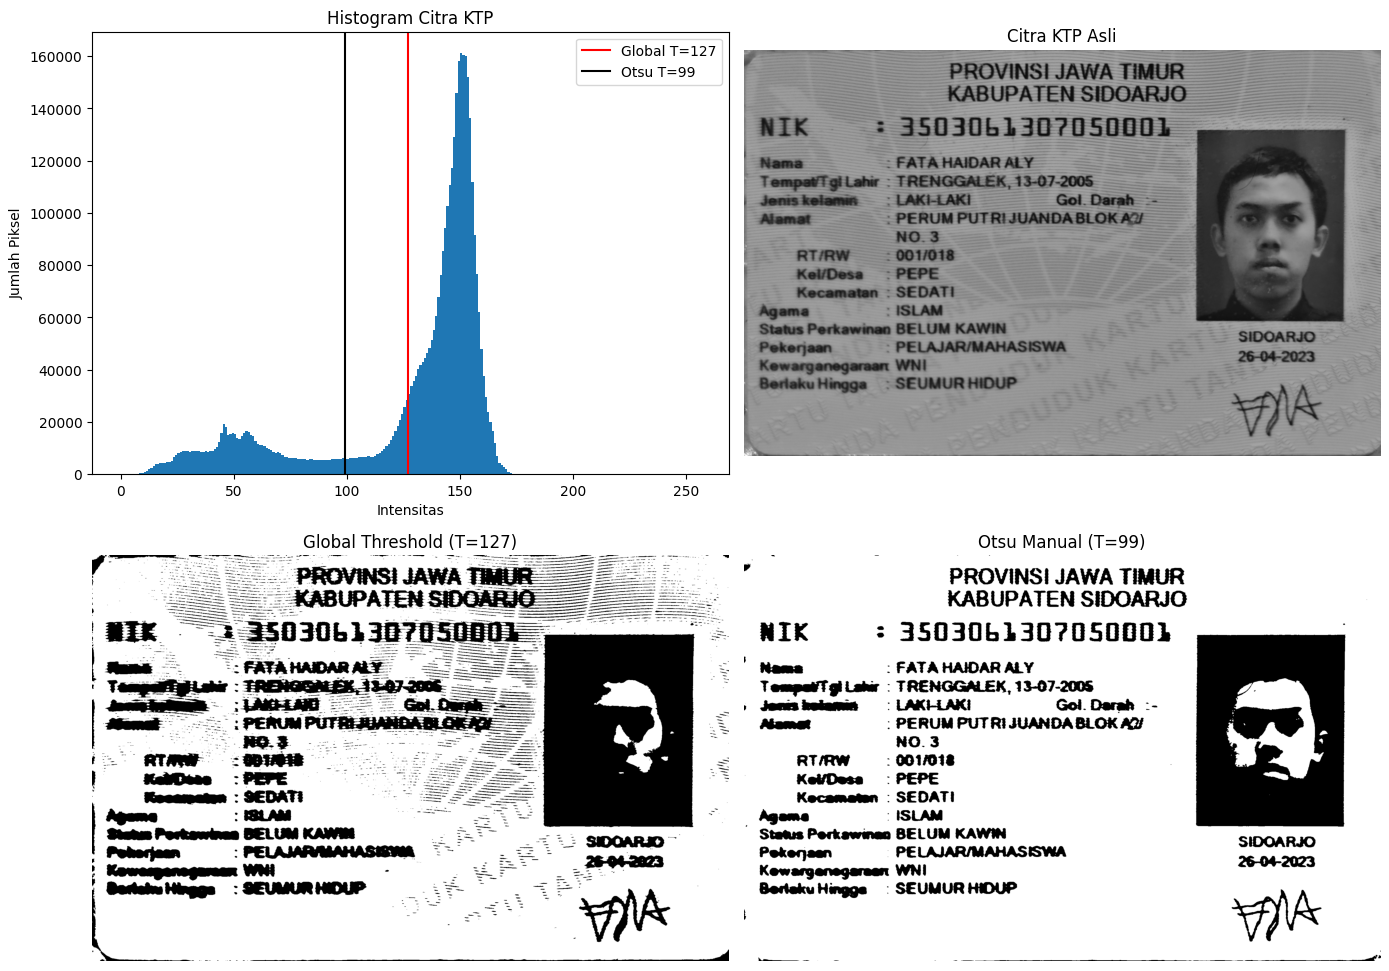

In [18]:
# Lokasi gambar
BASE = '/content/drive/MyDrive/PCVK'

# Membaca citra KTP
filename = f'{BASE}/ktpku.jpg'
img = cv.imread(filename, 0)

# Gaussian Blur
blur = cv.GaussianBlur(img, (5, 5), 0)
thresh = 127

# Global Threshold Manual
global_thresh = np.where(
    blur > thresh, 255, 0
).astype(np.uint8)

# Otsu Threshold Manual (fungsi dari Nomor 5A)
otsu_biner, otsu_thresh = otsu_manual(blur)

print("Global Threshold =", thresh)
print("Otsu Threshold =", otsu_thresh)
print("Intensitas minimum =", blur.min())
print("Intensitas maksimum =", blur.max())

# Menampilkan Histogram dan Hasil
plt.figure(figsize=(14, 10))

plt.subplot(2, 2, 1)
plt.hist(blur.ravel(), 256, [0, 256])
plt.axvline(thresh, color='red', label='Global T=127')
plt.axvline(otsu_thresh, color='black',
            label=f'Otsu T={otsu_thresh}')
plt.title('Histogram Citra KTP')
plt.xlabel('Intensitas')
plt.ylabel('Jumlah Piksel')
plt.legend()

titles = [
    'Citra KTP Asli',
    'Global Threshold (T=127)',
    f'Otsu Manual (T={otsu_thresh})'
]

images = [blur, global_thresh, otsu_biner]

for i in range(3):
    plt.subplot(2, 2, i + 2)
    plt.imshow(images[i], cmap='gray', vmin=0, vmax=255)
    plt.title(titles[i])
    plt.axis('off')

plt.tight_layout()
plt.show()


Pertanyaan :

1.Mengapa hasil tampilan Binary Thresholding semua bernilai 0 atau hitam
semuan?

2.Jelaskan alasannya dalam bentuk histogram dan berapa angka ambang batas
(Thresh) supaya gambar Lena ini masih terlihat?

Jawab :

1.Hasil Binary Thresholding menjadi hitam seluruhnya karena nilai threshold yang digunakan adalah 127, sedangkan intensitas piksel pada citra Lena lebih rendah dari 127. Akibatnya, seluruh piksel diubah menjadi nilai 0 (hitam).

2.Berdasarkan histogram, intensitas piksel citra Lena berada pada rentang sekitar 85–108, sehingga seluruhnya berada di sebelah kiri nilai threshold 127. Agar gambar Lena masih terlihat, nilai threshold dapat diturunkan menjadi sekitar 92, sehingga sebagian piksel menjadi hitam dan sebagian menjadi putih.

**6A. Segmentasi Berbasis Region (Region Growing Manual)**

Seed (baris, kolom): (36, 43)
Intensitas: 144.71


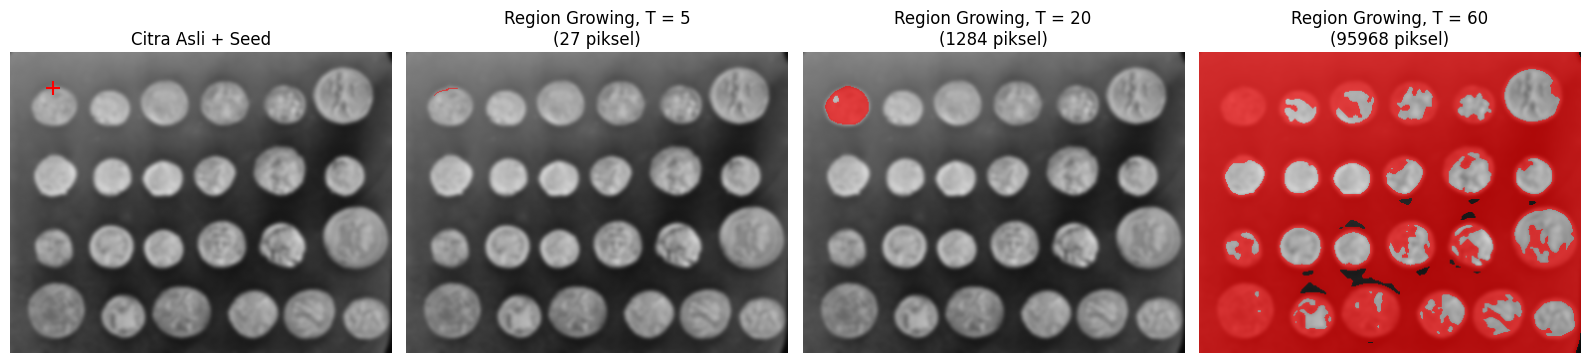

In [24]:
# Membaca citra coins
img = data.coins()

# Gaussian smoothing
img = gaussian(data.coins(), sigma=2, preserve_range=True)

# Seed di dalam koin
seed = (36, 43)
thresholds = [5, 20, 60]

print(f"Seed (baris, kolom): {seed}")
print(f"Intensitas: {img[seed]:.2f}")

# Menampilkan 1 baris (4 gambar)
fig, axes = plt.subplots(1, 4, figsize=(16, 4))

# Citra asli dengan titik seed
axes[0].imshow(img, cmap='gray', vmin=0, vmax=255)
axes[0].scatter(seed[1], seed[0],
                c='red', marker='+', s=100)
axes[0].set_title('Citra Asli + Seed')
axes[0].axis('off')

# Region Growing T = 5, 20, 60
for i, T in enumerate(thresholds):
    mask = region_growing(img, seed, T)

    overlay = np.zeros((*img.shape, 4))
    overlay[:, :, 0] = 1
    overlay[:, :, 3] = mask.astype(float) * 0.65

    axes[i + 1].imshow(img, cmap='gray', vmin=0, vmax=255)
    axes[i + 1].imshow(overlay)
    axes[i + 1].set_title(
        f'Region Growing, T = {T}\n({mask.sum()} piksel)'
    )
    axes[i + 1].axis('off')

plt.tight_layout()
plt.show()

**6B. Segmentasi Region menggunakan flood()**

Seed: (36, 43)
Intensitas: 159
Toleransi 5: 21 piksel
Toleransi 20: 919 piksel
Toleransi 60: 15253 piksel


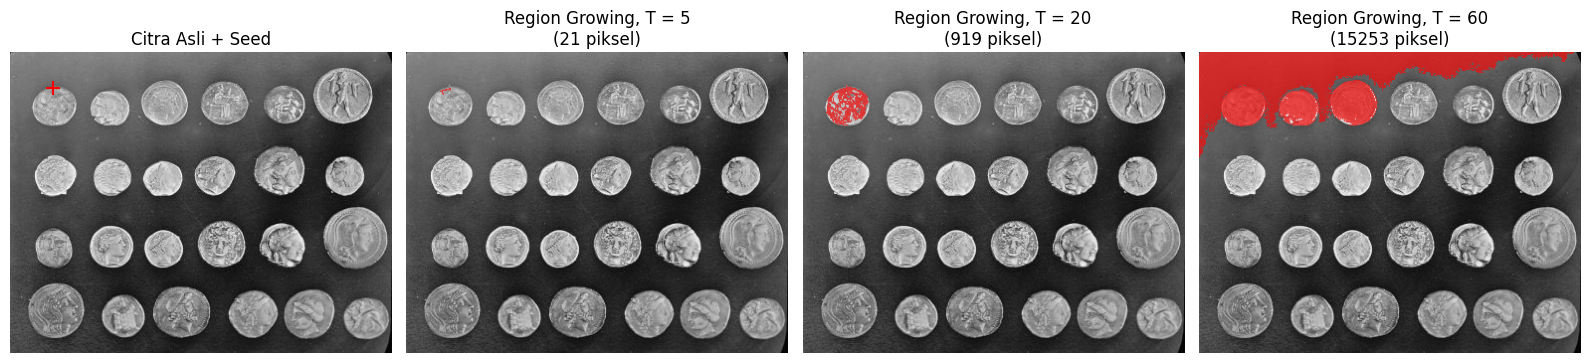

In [25]:
# Membaca citra coins
gray = data.coins()

# Seed (baris, kolom)
seed = (36, 43)
thresholds = [5, 20, 60]

print("Seed:", seed)
print("Intensitas:", gray[seed])

# Menampilkan hasil dalam 1 baris
fig, axes = plt.subplots(1, 4, figsize=(16, 4))

# Citra asli dan seed
axes[0].imshow(gray, cmap='gray')
axes[0].scatter(seed[1], seed[0],
                c='red', marker='+', s=100)
axes[0].set_title('Citra Asli + Seed')
axes[0].axis('off')

# Segmentasi menggunakan flood()
for i, T in enumerate(thresholds):
    region = flood(
        gray,
        seed_point=seed,
        tolerance=T,
        connectivity=1
    )

    print(f'Toleransi {T}: {region.sum()} piksel')

    # Overlay merah
    overlay = np.zeros((*gray.shape, 4))
    overlay[:, :, 0] = 1
    overlay[:, :, 3] = region.astype(float) * 0.65

    axes[i + 1].imshow(gray, cmap='gray')
    axes[i + 1].imshow(overlay)
    axes[i + 1].set_title(
        f'Region Growing, T = {T}\n'
        f'({region.sum()} piksel)'
    )
    axes[i + 1].axis('off')

plt.tight_layout()
plt.show()


**7. Segmentasi Warna Biru pada KTP**

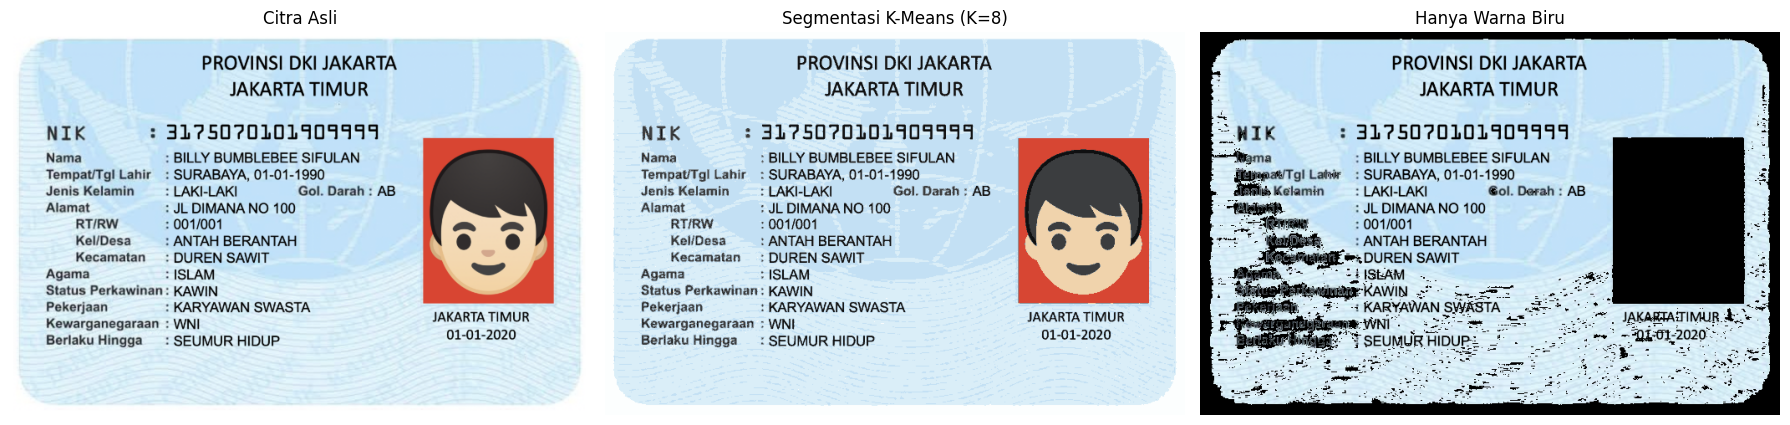

In [35]:
BASE = '/content/drive/MyDrive/PCVK'

# Membaca citra
filename = f'{BASE}/ktp_fulan.jpg'
img = cv.imread(filename)

if img is None:
    raise FileNotFoundError(filename)

# BGR -> RGB
rgb = cv.cvtColor(img, cv.COLOR_BGR2RGB)

# =========================
# 1. Segmentasi K-Means
# =========================
Z = rgb.reshape((-1, 3))
Z = np.float32(Z)

K = 8
criteria = (
    cv.TERM_CRITERIA_EPS + cv.TERM_CRITERIA_MAX_ITER,
    100, 0.2
)

_, labels, centers = cv.kmeans(
    Z, K, None, criteria, 10,
    cv.KMEANS_PP_CENTERS
)

centers = np.uint8(centers)
segmented = centers[labels.flatten()]
segmented_img = segmented.reshape(rgb.shape)

# =========================
# 2. Hanya warna biru
# =========================
hsv = cv.cvtColor(rgb, cv.COLOR_RGB2HSV)
H, S, V = cv.split(hsv)

kelompok_biru = np.where(
    (H >= 85) & (H <= 130) &
    (S >= 25) & (V >= 40)
)

mask = np.zeros(H.shape, dtype=np.uint8)
mask[kelompok_biru] = 255

hasil_biru = cv.bitwise_and(rgb, rgb, mask=mask)

# =========================
# 3. Tampilkan hasil
# =========================
titles = [
    'Citra Asli',
    'Segmentasi K-Means (K=8)',
    'Hanya Warna Biru'
]

images = [rgb, segmented_img, hasil_biru]

plt.figure(figsize=(18, 5))

for i in range(3):
    plt.subplot(1, 3, i + 1)
    plt.imshow(images[i])
    plt.title(titles[i])
    plt.axis('off')

plt.tight_layout()
plt.show()

**D2. Tugas Kelompok**

In [38]:
!apt-get -qq update
!apt-get -qq install -y tesseract-ocr tesseract-ocr-ind
!pip install -q pytesseract

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Selecting previously unselected package tesseract-ocr-ind.
(Reading database ... 122815 files and directories currently installed.)
Preparing to unpack .../tesseract-ocr-ind_1%3a4.1.0-2_all.deb ...
Unpacking tesseract-ocr-ind (1:4.1.0-2) ...
Setting up tesseract-ocr-ind (1:4.1.0-2) ...


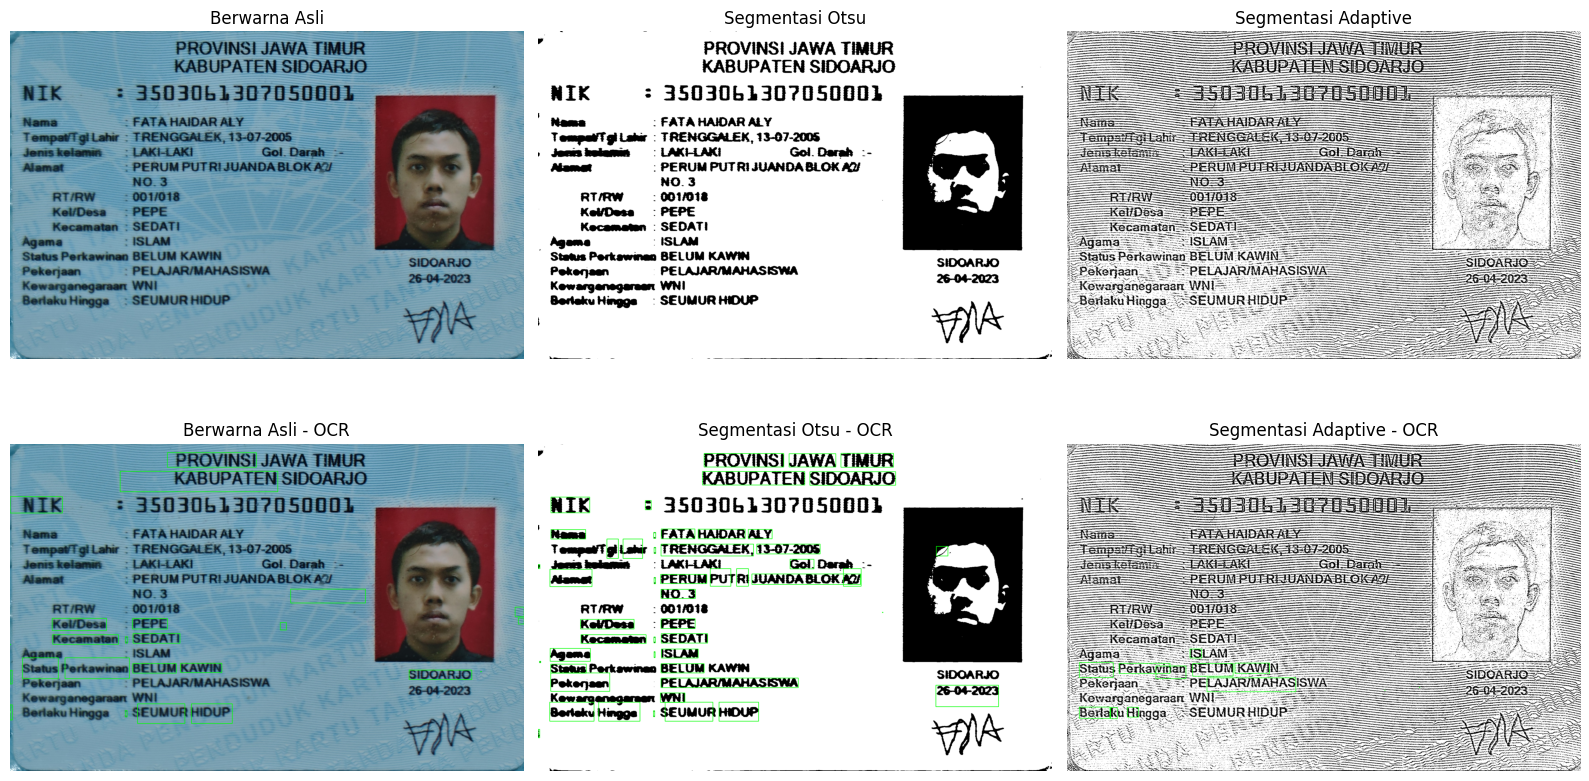


HASIL OCR: Berwarna Asli
V0 PROVINSI JAWA TIMUR”
0 KABUPATEN SIDOARJO”——————
NIK 3: 3503061307050001 sg jo
e Alamat: PERUM PUTRIJUANDABLOKAY ——  .
PS 3 — ——— Nun BE
AA aa aa -- 2
' Kel/Desa - PEPE — — — ——— .. 2
| Kecamatan : SEDATI 5 ———

Status Perkawinan BELUM KAWIN 5 —-- |

| -#ekerjaan PELAJAR BAHASA 5 55 SIDOARJO

| Berlaku Hingga : SEUMUR HIDUP BP A/

Ra Aa PPAS ea Aa — AA


HASIL OCR: Segmentasi Otsu
PROVINSI JAWA TIMUR
KABUPATEN SIDOARJO
NIK : 35030613070509D1
— Nama - FATA HAIDAR ALY
TempatT gi Lah - TRENGGALEK, 13-07-2005 A
| Jemabelamin LAKI-LAKI Gol. Darah --
Alamat : PERUM PUT RI JUANDABLOK AY 1. 3.
NO.3 :
RTRW - 0017018 | as
KeDasa : PEPE —
Kecamatan : SEDATI
. Agama : ISLAM
Status Perkawinan BELUM KAWIN SIDOARJO
Pekerjaan — PELAJAR/MAHASISWA
Kewarganegaraan WNI 26-04-2023
Bertaku Hingga : SEUMUR HIDUP ' |
|


HASIL OCR: Segmentasi Adaptive
P— Ka men aa Nan Dn
PN aa mn ee
- "1 - F1 3—3 & SN G7 Lan Pang 2
SP SABUPA PEN SIbaage
Y. 7 La
Aa Ahn et pg “UU
SA aa 33 AA TA EA A

In [39]:
# ============================================================
# D2. TUGAS KELOMPOK - OCR CITRA KTP
# ============================================================

import cv2 as cv
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pytesseract
from google.colab import drive
from IPython.display import display

# ============================================================
# 1. MEMBACA CITRA KTP
# ============================================================

filename = '/content/drive/MyDrive/PCVK/ktpku.jpg'

img = cv.imread(filename)

if img is None:
    raise FileNotFoundError("Gambar KTP tidak ditemukan!")

rgb = cv.cvtColor(img, cv.COLOR_BGR2RGB)
gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)


# ============================================================
# 2. SEGMENTASI OTSU DAN ADAPTIVE THRESHOLD
# ============================================================

# Otsu Thresholding
blur = cv.GaussianBlur(gray, (5, 5), 0)

nilai_otsu, otsu = cv.threshold(
    blur, 0, 255,
    cv.THRESH_BINARY + cv.THRESH_OTSU
)

# Adaptive Thresholding
adaptive = cv.adaptiveThreshold(
    gray, 255,
    cv.ADAPTIVE_THRESH_GAUSSIAN_C,
    cv.THRESH_BINARY,
    11, 2
)

# Tiga citra dengan ukuran sama
citra = {
    "Berwarna Asli": rgb,
    "Segmentasi Otsu": otsu,
    "Segmentasi Adaptive": adaptive
}


# ============================================================
# 3. OCR MENGGUNAKAN PYTESSERACT
# ============================================================

config = '--oem 3 --psm 6'
hasil = {}

for nama, gambar in citra.items():

    teks = pytesseract.image_to_string(
        gambar,
        lang='ind',
        config=config
    )

    data_ocr = pytesseract.image_to_data(
        gambar,
        lang='ind',
        config=config,
        output_type=pytesseract.Output.DICT
    )

    hasil[nama] = {
        "teks": teks,
        "data": data_ocr
    }


# ============================================================
# 4. MENAMPILKAN CITRA DAN KOTAK HIJAU
# ============================================================

fig, axes = plt.subplots(2, 3, figsize=(16, 9))

for i, (nama, gambar) in enumerate(citra.items()):

    # Baris pertama: citra masukan
    axes[0, i].imshow(
        gambar,
        cmap='gray' if gambar.ndim == 2 else None
    )

    axes[0, i].set_title(nama)
    axes[0, i].axis('off')

    # Baris kedua: hasil OCR dengan kotak hijau
    if gambar.ndim == 2:
        box_img = cv.cvtColor(gambar, cv.COLOR_GRAY2RGB)
    else:
        box_img = gambar.copy()

    data_ocr = hasil[nama]["data"]

    for j, teks in enumerate(data_ocr["text"]):

        confidence = float(data_ocr["conf"][j])

        if teks.strip() and confidence > 60:

            x = data_ocr["left"][j]
            y = data_ocr["top"][j]
            w = data_ocr["width"][j]
            h = data_ocr["height"][j]

            cv.rectangle(
                box_img,
                (x, y),
                (x + w, y + h),
                (0, 255, 0),
                2
            )

    axes[1, i].imshow(box_img)
    axes[1, i].set_title(nama + " - OCR")
    axes[1, i].axis('off')

plt.tight_layout()
plt.show()


# ============================================================
# 5. MENAMPILKAN HASIL PEMBACAAN TEKS
# ============================================================

for nama in citra:

    print("\n====================================")
    print("HASIL OCR:", nama)
    print("====================================")

    print(hasil[nama]["teks"])

print("\nThreshold Otsu:", nilai_otsu)